In [1]:
# Langchain Simple Agent Tool Calling

---

## **Part 1: LangChain Framework – Core Architecture (Agentic Use Case Perspective)**

### **The Problem LangChain Solves**
LLMs (like GPT-4) are great at generating text, but:
- They can’t access tools like search, calculator, or your company data.
- They forget everything between messages unless you give them memory.
- They can't reason step-by-step or make decisions dynamically.

**LangChain solves this by acting as a bridge.**

---

### **LangChain Key Components (Agentic Perspective)**

| Component | What It Does | Real Example |
|----------|--------------|--------------|
| **LLM** | Connects to GPT-4, Claude, Mistral, etc. | "Write an email to HR" |
| **PromptTemplate** | Creates reusable prompt structures | "Write a tweet about {topic}" |
| **Tool** | External actions (Search, API call, DB) | Weather lookup, PDF reader |
| **Agent** | Decides *when* and *how* to use tools | "Hmm… to answer this, I need weather + location" |
| **Memory** | Stores past conversations | Multi-turn chatbots |
| **Retriever** | Retrieves documents from a knowledge base | Vector search in RAG |
| **Chain** | Links LLM calls together in steps | Extract from PDF → Generate summary → Send email |

---

### **Visual Architecture: Simple Agentic System**

```
[User Query]
     |
     v
[LangChain Agent] --- decides --->
     |                           |
     |                          [Tool 1: Weather API]
     |                          [Tool 2: Flight Search]
     |                          [Tool 3: Calculator]
     |
[Final Answer to User]
```


---

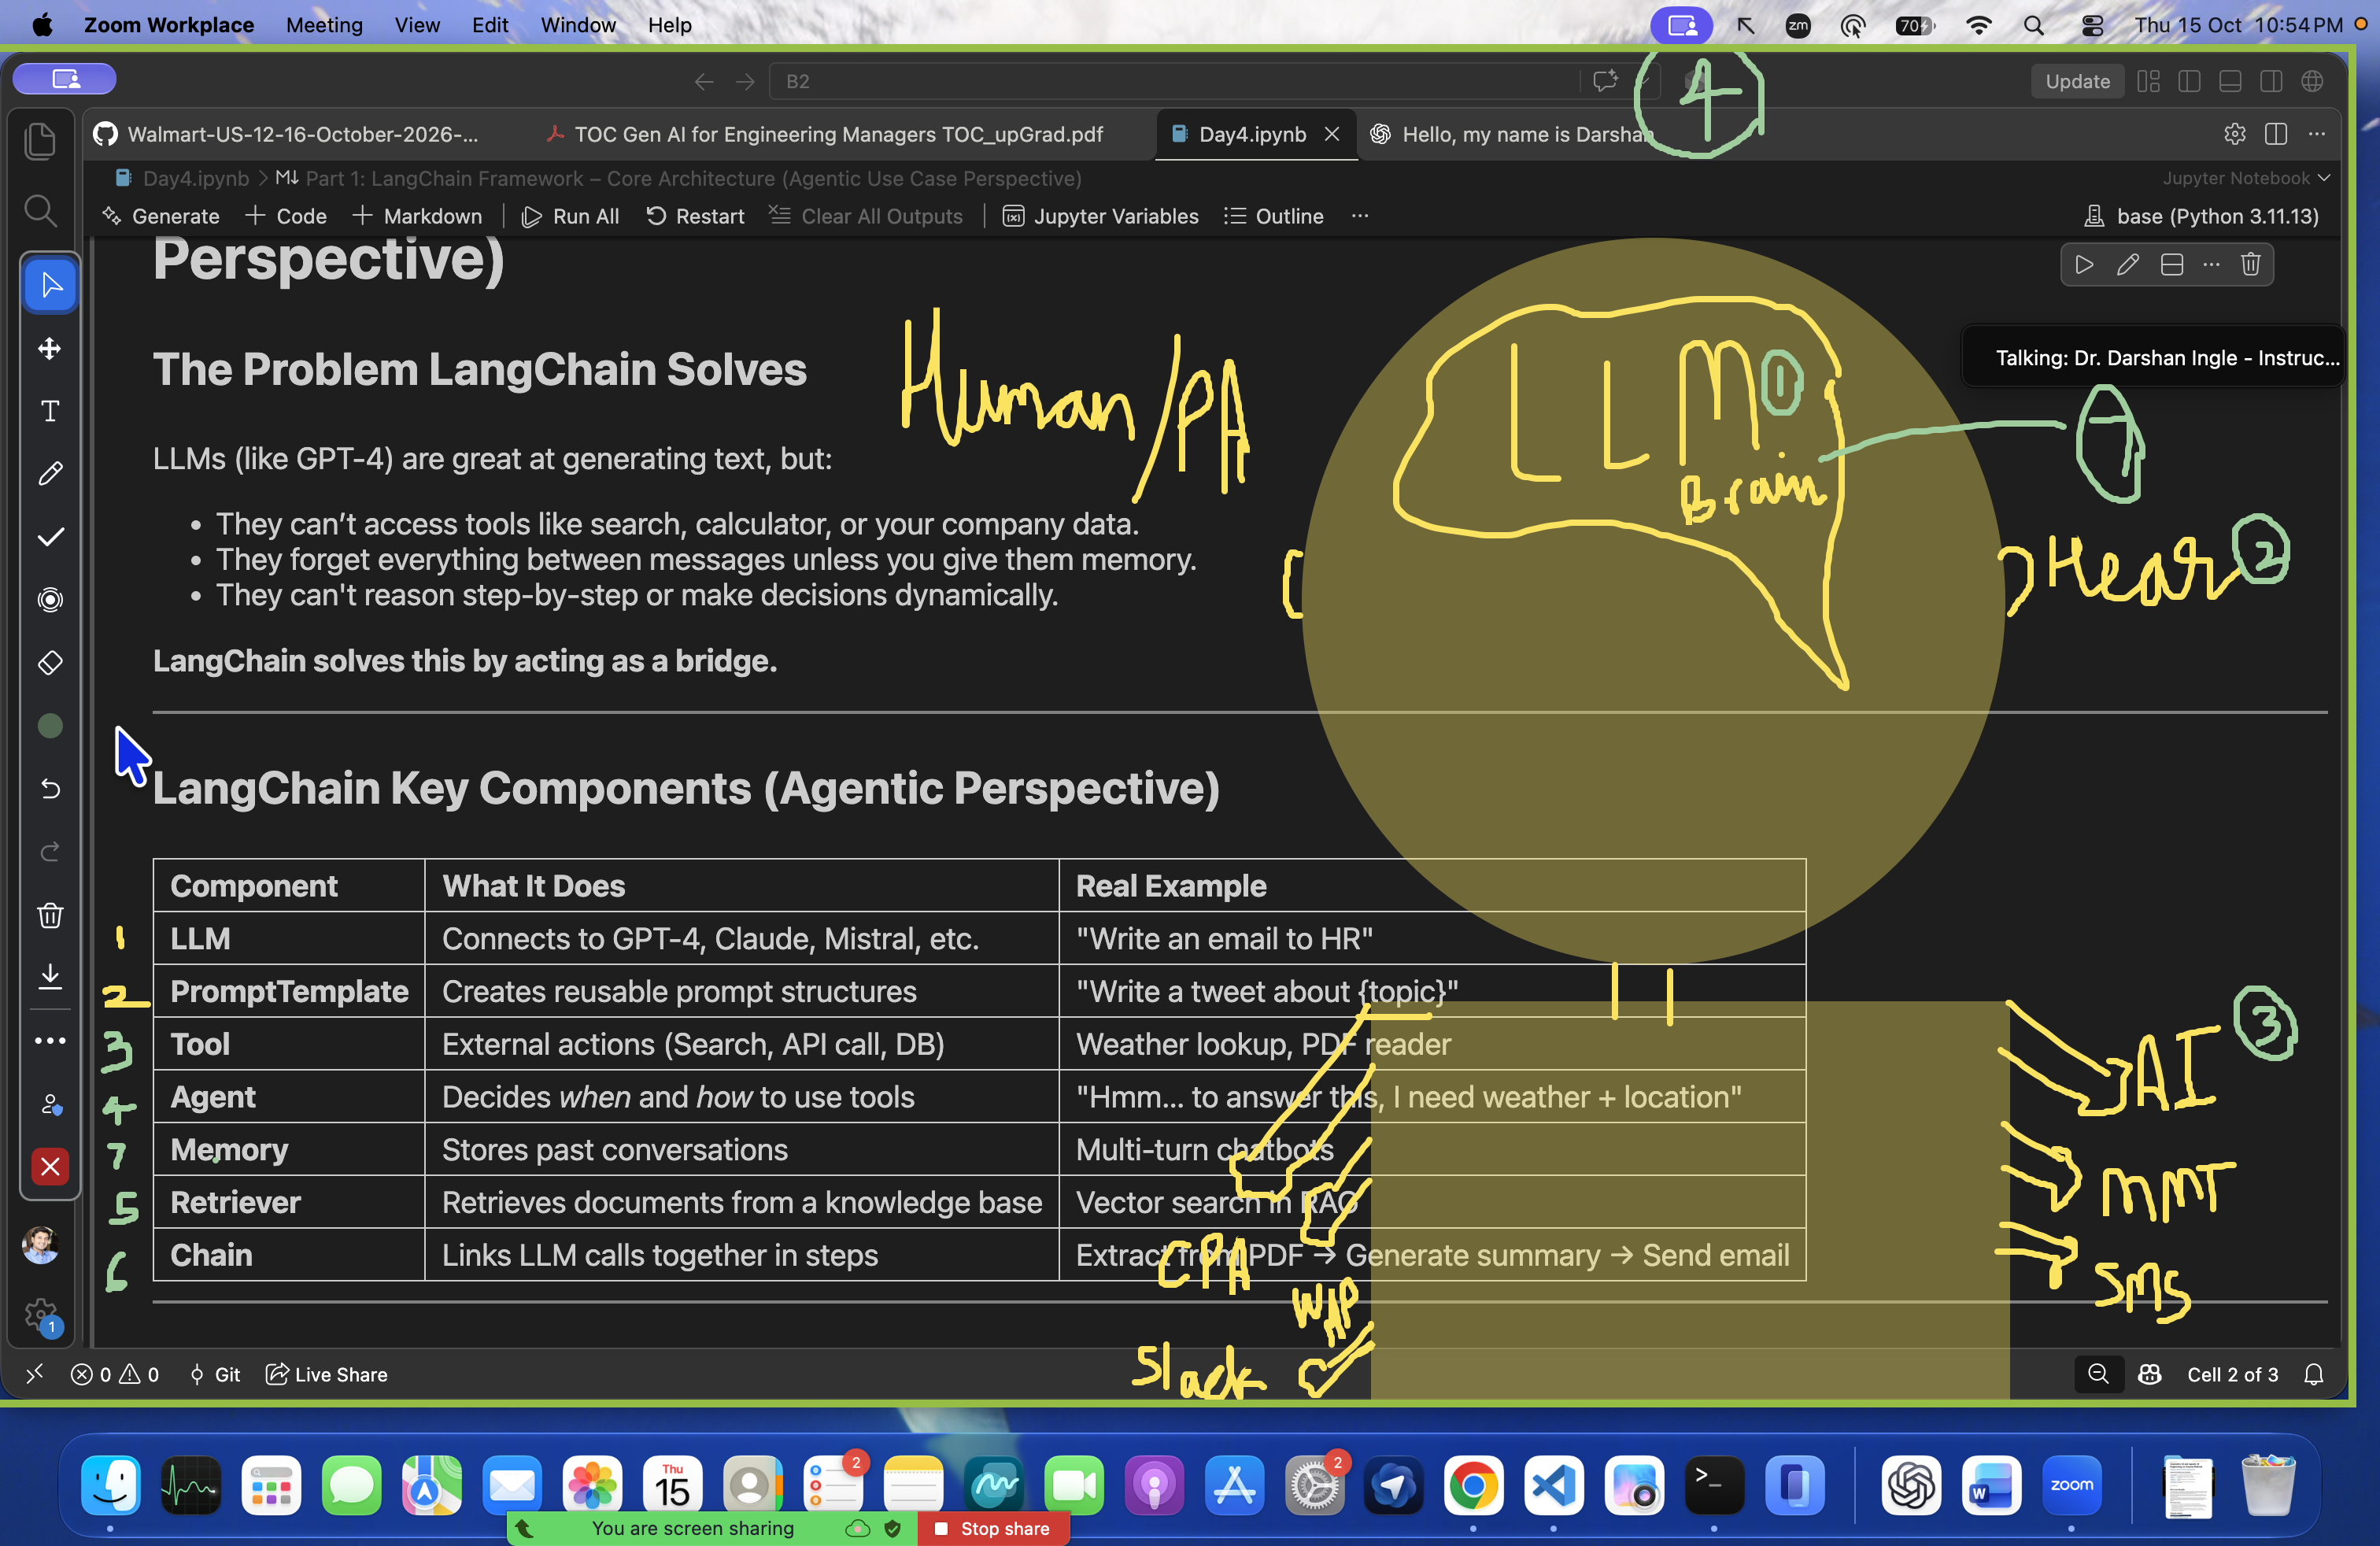



---

## **Problem Statement**

In many real-world scenarios, users seek contextual information about the current date and time as part of their natural language queries. For example:

* *“What is today’s date?”*
* *“Can you tell me the current time before I schedule a meeting?”*

While large language models (LLMs) can generate approximate or static answers, they are **not inherently aware of real-time system information**. As a result, they may provide outdated or fabricated responses when asked about the current date or time.

To ensure accuracy, an intelligent assistant must:

1. **Understand natural language queries referring to temporal context.**
2. **Automatically invoke tools that fetch real-time system date and time.**
3. **Integrate tool outputs into a conversational, human-friendly response.**

This functionality is crucial in **productivity tools, scheduling assistants, personal reminders, and business applications**, where real-time awareness significantly enhances user experience and reliability.

---

## **Objective**

Design and implement a **LangChain-powered agent** that integrates real-time utilities for date and time. The agent should:

* **Detect** when a user query involves current date or time.
* **Automatically call the appropriate tool** (`get_current_date` or `get_current_time`).
* **Leverage LangChain’s tool-calling framework** to handle reasoning and orchestration.
* **Maintain a reasoning trace** using `agent_scratchpad` for clarity.
* **Provide responses** in a conversational and context-aware format, ensuring outputs are both precise and user-friendly.

---



In [2]:
# !pip install -U \
# langchain==0.3.27 \
# langchain-core==0.3.79 \
# langchain-community==0.3.31 \
# langchain-openai==0.3.35 \
# langchain-text-splitters==0.3.9 \
# langchainhub \
# faiss-cpu \
# sentence-transformers -q

In [3]:
# Agent components:
# 1. Brain: LLM (e.g., GPT-4, Claude 3)
# 2. Prompt Template: Guides the LLM's responses.
# 3. Tools: Functions the agent can call to perform tasks.
# 4. Memory: Stores context from previous interactions.

In [4]:
# Langchain Simple Agent

# Import required libraries

# For calling the Openai API
from langchain_openai import ChatOpenAI # LLM BRAIN - ENGINE

from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder # MESSAGES - CHASSIS
# ChatPromptTemplate: It is used to create a prompt template for chat models. This helps in structuring the input for the model.
# MessagesPlaceholder: It is used to indicate where the messages should be placed in the prompt template. This allows for dynamic insertion of messages during the conversation.

from langchain.tools import tool # HANDS - DASHBOARD
# tool: It is used to define a tool that can be called by the agent. This allows the agent to perform specific actions or retrieve information.

from langchain.agents import create_tool_calling_agent, AgentExecutor
# create_tool_calling_agent: It is used to create an agent that can call tools. This allows the agent to use the defined tools to perform tasks.
# AgentExecutor: It is used to execute the agent. This allows the agent to process inputs

In [5]:
# Load the environment variables from the .env file
from dotenv import load_dotenv
load_dotenv()  # Load environment variables from .env file

True

In [6]:
import os, requests, json
WEATHER_KEY = os.getenv('OPENWEATHERMAP_API_KEY')

In [7]:
def fetch_weather(city: str, country_code: str = 'IN') -> dict:
    # Call the live OpenWeatherMap API for current weather.
    url    = 'https://api.openweathermap.org/data/2.5/weather'
    params = {'q': f'{city},{country_code}', 'appid': WEATHER_KEY, 'units': 'metric'} # units=metric for Celsius, units=imperial for Fahrenheit
    resp   = requests.get(url, params=params, timeout=10)
    resp.raise_for_status()
    d = resp.json()
    print("\n\n")
    print("Debugging Lines:")
    print(d)
    print("\n\n")
    return {
        'city':           d['name'],
        'country':        d['sys']['country'],
        'temperature_c':  round(d['main']['temp'], 1),
        'feels_like_c':   round(d['main']['feels_like'], 1),
        'humidity_pct':   d['main']['humidity'],
        'condition':      d['weather'][0]['description'],
        'condition_main': d['weather'][0]['main'],
        'wind_speed_ms':  d['wind']['speed'],
        'pressure_hpa':   d['main']['pressure'],
    }

fetch_weather('Mumbai', 'IN')




Debugging Lines:
{'coord': {'lon': 72.8479, 'lat': 19.0144}, 'weather': [{'id': 804, 'main': 'Clouds', 'description': 'overcast clouds', 'icon': '04n'}], 'base': 'stations', 'main': {'temp': 28.98, 'feels_like': 31.8, 'temp_min': 28.98, 'temp_max': 28.98, 'pressure': 1010, 'humidity': 65, 'sea_level': 1010, 'grnd_level': 1010}, 'visibility': 10000, 'wind': {'speed': 1.96, 'deg': 24, 'gust': 2.33}, 'clouds': {'all': 100}, 'dt': 1792088330, 'sys': {'country': 'IN', 'sunrise': 1792026146, 'sunset': 1792068371}, 'timezone': 19800, 'id': 1275339, 'name': 'Mumbai', 'cod': 200}





{'city': 'Mumbai',
 'country': 'IN',
 'temperature_c': 29.0,
 'feels_like_c': 31.8,
 'humidity_pct': 65,
 'condition': 'overcast clouds',
 'condition_main': 'Clouds',
 'wind_speed_ms': 1.96,
 'pressure_hpa': 1010}

In [8]:
llm = ChatOpenAI(model="gpt-4o")
# https://python.langchain.com/docs/integrations/chat/openai/

In [9]:
# Step 5: Create prompt template (IMPORTANT: include input & agent_scratchpad)

prompt = ChatPromptTemplate.from_messages([
    ("system", "You are a smart assistant. You can use tools whenever necessary to answer user questions."),
    ("user", "{input}"),
    MessagesPlaceholder(variable_name="agent_scratchpad")  # Required
    # MessagesPlaceholder - A special placeholder used by LangChain agents to store: a. Intermediate reasoning steps, b. Tool calls, c. Tool outputs - ReAct Style (Thoughts, Actions, and Observations)
])

In [10]:
from datetime import datetime

now = datetime.now()
print("Date:", now.strftime("%Y-%m-%d"))
print("Time:", now.strftime("%H:%M:%S"))

Date: 2026-10-16
Time: 00:01:28


In [11]:
# Install pendulum package for timezone handling
# !pip install pendulum -q

import pendulum

now = pendulum.now("Asia/Kolkata")
print("Date:", now.format("YYYY-MM-DD"))
print("Time:", now.format("HH:mm:ss"))

Date: 2026-10-16
Time: 00:01:28


In [12]:
# eval()
# What is eval() in Python?
# eval() is a built-in function in Python that parses the expression passed to it and runs python expression (code) within the program. The expression is parsed and evaluated as a Python expression,
# and the result of the evaluation is returned. The eval() function can evaluate any valid Python expression, including mathematical operations, function calls, and variable references. It can also be used to evaluate expressions that are dynamically generated at runtime. However, it should be used with caution, as it can execute arbitrary code and pose security risks if used with untrusted input.

print(eval("65 + 35"))  
print(eval("65 + 35 * 2"))
print(eval("65 + 35 * 2 / 5"))
print(eval("65 + 35 * 2 / 5 - 10"))

100
135
79.0
69.0


In [13]:
# Tool Definitions
import pendulum

@tool
def get_current_date_in_india():
    """Returns the current date in India (IST timezone)."""
    now = pendulum.now("Asia/Kolkata")
    return f"Current date in India (IST): {now.format('YYYY-MM-DD')}"

@tool
def get_current_time_in_india():
    """Returns the current time in India (IST timezone)."""
    now = pendulum.now("Asia/Kolkata")
    return f"Current time in India (IST): {now.format('HH:mm:ss')}"

@tool
def calculate_simple_expression(expression: str):
    """Evaluates a simple mathematical expression."""
    try:
        result = eval(expression)
        return f"The result of the expression '{expression}' is: {result}"
    except Exception as e:
        return f"Error evaluating the expression '{expression}': {e}"

@tool
def fetch_weather(city: str, country_code: str = 'IN') -> dict:
    """Fetch current weather data for a given city and country code."""
    url    = 'https://api.openweathermap.org/data/2.5/weather'
    params = {'q': f'{city},{country_code}', 'appid': WEATHER_KEY, 'units': 'metric'}
    resp   = requests.get(url, params=params, timeout=10)
    resp.raise_for_status()
    d = resp.json()
    print("\n\n")
    print("Debugging Lines:")
    print(d)
    print("\n\n")
    return {
        'city':           d['name'],
        'country':        d['sys']['country'],
        'temperature_c':  round(d['main']['temp'], 1),
        'feels_like_c':   round(d['main']['feels_like'], 1),
        'humidity_pct':   d['main']['humidity'],
        'condition':      d['weather'][0]['description'],
        'condition_main': d['weather'][0]['main'],
        'wind_speed_ms':  d['wind']['speed'],
        'pressure_hpa':   d['main']['pressure'],
    }

tools = [get_current_date_in_india, get_current_time_in_india, calculate_simple_expression, fetch_weather]

In [14]:
 agent = create_tool_calling_agent(
    llm=llm,
    tools=tools,
    prompt=prompt
)

In [15]:
# Wrap the agent in an AgentExecutor
agent_executor = AgentExecutor(
    agent=agent,
    tools=tools,
    verbose=True # Set verbose=True to see the agent's reasoning and tool calls in the output
)

In [ ]:
response = agent_executor.invoke({"input": "Explain the process of photosynthesis in 5 lines."})
print(response['output'])
# print(response)

# How does the Agent work?
# 1. The user provides an input query to the agent.
# 2. The query "input" is passed to the agent's prompt template, which structures the input for the LLM.
# 3. This structured prompt is then sent to the LLM (e.g., GPT-4) for processing. LLM is good at understanding and generating human-like text based on the input it receives.
# 4. The LLM processes the input and looks for any tool calls if available. If the LLM determines that a tool is available, then it will call the tool with the appropriate parameters and get back the output from the tool. However, if the LLM determines that no tool is available, then it will see if it can answer the question itself based on its training data and the context provided in the prompt. If it can answer the question, it will generate a response directly. If it cannot answer the question, it will generate a response indicating that it cannot answer the question.
# 5. If the tool is called, the output from the tool is then passed back to the LLM as part of the agent's scratchpad (intermediate reasoning steps). The LLM can then use this information to generate a final response to the user's query.
# 6. The final response is then returned to the user.

# Ques -> AGENT(llm+tools+prompt) -> Prompt -> llm(brain) -> check for tools -> No tools -> llm(brain) -> Can I answer? -> Yes/No -> If No -> I cannot answer. If Yes -> Generate response -> Return response to user

In [ ]:
response = agent_executor.invoke({"input": "Explain the process of photosynthesis in 5 bullet points."})
print(response['output'])


In [ ]:
response = agent_executor.invoke({"input": "What is the capital of India?"})
print(response['output'])


In [ ]:
response = agent_executor.invoke({"input": "What is the capital of New Delhi?"})
print(response['output'])


In [ ]:
response = agent_executor.invoke({"input": "My name is Darshan and I want to become a data scientist. Please guide me with three successful career tips."})
print(response['output'])


In [ ]:
response = agent_executor.invoke({"input": "What is the capital of New York?"})
print(response['output'])


In [ ]:
response = agent_executor.invoke({"input": "Do do you recollect my name?"})
print(response['output'])


In [ ]:
response = agent_executor.invoke({"input": "My name is Darshan and I want to become a data scientist. Please guide me with three successful career tips. At the end, give me a personalised tip, mentioning my name."})
print(response['output'])


In [ ]:
response = agent_executor.invoke({"input": "Do do you recollect my name?"})
print(response['output'])


In [ ]:
response = agent_executor.invoke({"input": "What is today's date in India?"}) # 15th Oct 2026, 11:17pm IST
print(response['output'])

In [ ]:
response = agent_executor.invoke({"input": "What is today's date in India?"}) # 15th Oct 2026, 11:17pm IST
print(response['output'])

In [ ]:
response = agent_executor.invoke({"input": "What is today's date in India?"}) # 15th Oct 2026, 11:17pm IST
print(response['output'])

In [ ]:
response = agent_executor.invoke({"input": "What is today's date and time in India?"}) # 15th Oct 2026, 11:17pm IST
print(response['output'])

In [ ]:
response = agent_executor.invoke({"input": "Is it 15th October 2026 in India today?"})
print(response['output'])


In [ ]:
response = agent_executor.invoke({"input": "Is it Thursday today in India?"})
print(response['output'])


In [ ]:
response = agent_executor.invoke({"input": "What is today's date and time in Pakistan?"})
print(response['output'])

In [ ]:
response = agent_executor.invoke({"input": "What is today's date and time in NYC, USA?"})
print(response['output'])

In [ ]:
response = agent_executor.invoke({"input": "What is today's date and time in Winnipeg, Canada?"})
print(response['output'])

In [ ]:
response = agent_executor.invoke({"input": "What is today's date and time in Honalulu, USA?"})
print(response['output'])

In [ ]:
response = agent_executor.invoke({"input": "How many days have passed since the latest India's Independence Day?"})
print(response['output'])

# India's Independence Day - 15th August 2026

In [ ]:
response = agent_executor.invoke({"input": "How many days have passed since the latest India's Independence Day? Think step-by-step."})
print(response['output'])


In [ ]:
response = agent_executor.invoke({"input": "What is the current time in India 12 hour format?"})
print(response['output'])


In [ ]:
response = agent_executor.invoke({"input": "my training is supposed to get over at 12:30 AM IST tomorrow. Can you tell me how much time I have left to teach more??"})
print(response['output'])


In [ ]:
expr = 75621 * 321 / 12 + (4334-1234 + 4334 * 2) ** 2 / 74
print(expr)

In [ ]:
# 3,894,291.80.

In [ ]:
response = agent_executor.invoke({"input": "Solve this and tell me the final answer: 75621 * 321 / 12 + (4334-1234 + 4334 * 2) ** 2 / 74"})
print(response['output'])


In [16]:
response = agent_executor.invoke({"input": "what is the temperature in Mumbai right now?"})
print(response['output'])




> Entering new AgentExecutor chain...

Invoking: `fetch_weather` with `{'city': 'Mumbai'}`





Debugging Lines:
{'coord': {'lon': 72.8479, 'lat': 19.0144}, 'weather': [{'id': 804, 'main': 'Clouds', 'description': 'overcast clouds', 'icon': '04n'}], 'base': 'stations', 'main': {'temp': 28.98, 'feels_like': 31.8, 'temp_min': 28.98, 'temp_max': 28.98, 'pressure': 1010, 'humidity': 65, 'sea_level': 1010, 'grnd_level': 1010}, 'visibility': 10000, 'wind': {'speed': 1.96, 'deg': 24, 'gust': 2.33}, 'clouds': {'all': 100}, 'dt': 1792088918, 'sys': {'country': 'IN', 'sunrise': 1792112563, 'sunset': 1792154726}, 'timezone': 19800, 'id': 1275339, 'name': 'Mumbai', 'cod': 200}



{'city': 'Mumbai', 'country': 'IN', 'temperature_c': 29.0, 'feels_like_c': 31.8, 'humidity_pct': 65, 'condition': 'overcast clouds', 'condition_main': 'Clouds', 'wind_speed_ms': 1.96, 'pressure_hpa': 1010}The current temperature in Mumbai is 29.0°C, and it feels like 31.8°C. The weather is overcast with clouds, and the 

In [17]:
response = agent_executor.invoke({"input": "find out today's date in India and add to todays's date number the current temperature of Bangalore and print the result"})
print(response['output'])




> Entering new AgentExecutor chain...

Invoking: `get_current_date_in_india` with `{}`


Current date in India (IST): 2026-10-16
Invoking: `fetch_weather` with `{'city': 'Bangalore'}`





Debugging Lines:
{'coord': {'lon': 77.6033, 'lat': 12.9762}, 'weather': [{'id': 804, 'main': 'Clouds', 'description': 'overcast clouds', 'icon': '04n'}], 'base': 'stations', 'main': {'temp': 21.45, 'feels_like': 22.08, 'temp_min': 21.45, 'temp_max': 21.45, 'pressure': 1013, 'humidity': 93, 'sea_level': 1013, 'grnd_level': 915}, 'visibility': 6071, 'wind': {'speed': 3.53, 'deg': 123, 'gust': 6.33}, 'clouds': {'all': 100}, 'dt': 1792088975, 'sys': {'country': 'IN', 'sunrise': 1792111186, 'sunset': 1792153821}, 'timezone': 19800, 'id': 1277333, 'name': 'Bengaluru', 'cod': 200}



{'city': 'Bengaluru', 'country': 'IN', 'temperature_c': 21.4, 'feels_like_c': 22.1, 'humidity_pct': 93, 'condition': 'overcast clouds', 'condition_main': 'Clouds', 'wind_speed_ms': 3.53, 'pressure_hpa': 1013}
Invoking: `calcu

# Happy Learning